# 04 | Monte Carlo als Trefferquote

**Frage:** Wie lässt sich eine Fläche durch zufällige Punkte schätzen?

**Lernziele:** Sie erkennen Treffer, berechnen eine Trefferquote und
erklären den Faktor vier bei der Schätzung von pi.

**Vorwissen aus Termin 2 und 3:** Variablen, Listen, Schleifen,
Funktionen und Seed. Hilfe: `** 2` bedeutet quadrieren, `<=` bedeutet
kleiner oder gleich. Ein Seed macht eine Zufallsfolge reproduzierbar;
er macht eine Schätzung nicht automatisch richtig.

**Arbeitszeit:** 10 Minuten Demo, dann 30 Minuten Eigenarbeit.
**Geplante Rechenzeit:** wenige Sekunden für alle voreingestellten Zellen.
Python mit Matplotlib wird benötigt. In VS Code die Kursumgebung als
Kernel auswählen. Keine Downloads oder anderen Dateien erforderlich.
Führen Sie die Zellen von oben nach unten aus. Das Basisexperiment
ist vollständig; die Aufgaben verlangen eigene Erweiterungen.

In [1]:
from random import Random
import math
import sys

import matplotlib.pyplot as plt

print("Verwendetes Python:", sys.executable)

Verwendetes Python: f:\Uni\Simulationstools\.venv\Scripts\python.exe


## 1. Erst rechnen, dann programmieren

Ein Punkt besteht aus zwei Koordinaten zwischen 0 und 1. Der Viertelkreis
hat Radius 1. Ein Punkt ist ein Treffer, wenn die Summe der quadrierten
Koordinaten höchstens 1 ist. Der Rand zählt mit.
Die erste Koordinate beschreibt die Lage nach rechts, die zweite nach oben.
Quadrieren heißt mit sich selbst multiplizieren: 0.3 ** 2 = 0.3 * 0.3.

**Vorhersage:** Ist (0.3, 0.4) ein Treffer? Und (0.8, 0.8)?
Rechnen Sie vor dem Start der nächsten Zelle.

In [2]:
def im_viertelkreis(koordinate_x, koordinate_y):
    return koordinate_x ** 2 + koordinate_y ** 2 <= 1


print("Punkt (0.3, 0.4):", im_viertelkreis(0.3, 0.4))
print("Punkt (0.8, 0.8):", im_viertelkreis(0.8, 0.8))

Punkt (0.3, 0.4): True
Punkt (0.8, 0.8): False


`def` definiert eine Funktion. Die beiden Namen in Klammern sind ihre
Eingaben. `return` liefert das Ergebnis zurück. `True` bedeutet Treffer,
`False` bedeutet kein Treffer. Die Summen sind 0.25 und 1.28.

In der folgenden Liste steht jedes Klammerpaar für einen Punkt.
`for koordinate_x, koordinate_y in punkte` nimmt in jedem Durchlauf
genau ein Paar auseinander. Die zwei Zahlen bekommen lesbare Namen.

In [3]:
punkte = [(0, 0), (1, 0), (0, 1), (0.8, 0.8), (0.3, 0.4)]
treffer = 0
for koordinate_x, koordinate_y in punkte:
    quadratsumme = koordinate_x ** 2 + koordinate_y ** 2
    ist_treffer = im_viertelkreis(koordinate_x, koordinate_y)
    print(koordinate_x, koordinate_y, round(quadratsumme, 2), ist_treffer)
    if ist_treffer:
        treffer += 1

quote = treffer / len(punkte)
print("Treffer:", treffer, "von", len(punkte))
print("Quote:", quote, "Pi-Rechenergebnis:", 4 * quote)

0 0 0 True
1 0 1 True
0 1 1 True
0.8 0.8 1.28 False
0.3 0.4 0.25 True
Treffer: 4 von 5
Quote: 0.8 Pi-Rechenergebnis: 3.2


`treffer += 1` erhöht den Zähler um eins. `len(punkte)` zählt **alle**
Punkte, auch die außerhalb des Kreises. `round(..., 2)` rundet nur die
Anzeige, nicht die Entscheidung. Es sind vier Treffer aus fünf Punkten:
Quote 0.8, Rechenergebnis 3.2.

**Warum mal vier?** Ein Kreis mit Radius 1 hat Fläche pi (etwa 3.14).
Gezeichnet ist ein Viertel dieses Kreises, also Fläche pi/4.
Das Quadrat hat Fläche 1 * 1 = 1.
Bei unabhängigen gleichverteilten Punkten nähert die Trefferquote
diesen Flächenanteil an. Also: Pi-Schätzung = 4 * Treffer / alle Punkte.
Die feste Liste prüft nur die Rechnung, nicht die Zufallsqualität.

**Verständnisstopp:** Warum funktioniert die Flächenschätzung nicht,
wenn wir absichtlich nur Punkte nahe (0, 0) auswählen?
Diese Auswahl bevorzugt Treffer; sie repräsentiert das Quadrat nicht.

## 2. Ein vollständiger Simulationslauf

`Random(seed)` erzeugt einen lokalen Zufallsgenerator. `random()` liefert
eine Zahl zwischen 0 einschließlich und 1 ausschließlich.
Zwei aufeinanderfolgende Ziehungen bilden einen Punkt. Für dieses
Lehrmodell verwenden wir sie als unabhängige gleichverteilte Koordinaten.

`anzahl` ist eine positive ganze Zahl. `range(anzahl)` wiederholt den
eingerückten Block entsprechend oft. Ein Lauf besteht aus vielen Punkten.
Der Seed wird **einmal vor** der Schleife gesetzt, nicht bei jedem Punkt.

In [4]:
def schaetze_pi(anzahl, seed):
    if anzahl <= 0:
        raise ValueError("anzahl muss positiv sein")
    generator = Random(seed)
    treffer = 0
    for versuch in range(anzahl):
        koordinate_x = generator.random()
        koordinate_y = generator.random()
        if im_viertelkreis(koordinate_x, koordinate_y):
            treffer += 1
    return 4 * treffer / anzahl


anzahl = 20000
seed = 2026
pi_schaetzung = schaetze_pi(anzahl, seed)
print("Punkte:", anzahl, "Seed:", seed)
print("Schaetzung:", pi_schaetzung)
print("Referenz:", math.pi)
print("Absolute Abweichung:", abs(pi_schaetzung - math.pi))

Punkte: 20000 Seed: 2026
Schaetzung: 3.158
Referenz: 3.141592653589793
Absolute Abweichung: 0.016407346410206802


In [5]:
def Doppelwert(x, y):
    # Hier Ihren Funktionscode einrücken, z.B.:
    x_neu = x ** 2
    y_neu = y ** 2
    if x_neu + y_neu <= 1:
        return True
    else:
        return False

Doppelwert(0.3, 0.4)


True

`raise ValueError(...)` beendet den Aufruf mit einer verständlichen
Meldung, falls der Nenner unzulässig ist. Im Basislauf tritt das nicht auf.
`math.pi` ist die bekannte Vergleichszahl. `abs(...)` nimmt den Betrag:
Über- und Unterschätzung erhalten so eine positive Abweichung.

**Vorhersage:** Ändert sich die Ausgabe bei gleichem Seed und gleicher
Anzahl in derselben Umgebung? Testen wir es, ohne die Parameter zu ändern.

In [6]:
wiederholung = schaetze_pi(anzahl, seed)
print("Gleiches Ergebnis:", pi_schaetzung == wiederholung)

Gleiches Ergebnis: True


Das Ergebnis ist gleich: Jeder Funktionsaufruf beginnt mit derselben
Zufallsfolge. Das ist eine Reproduzierbarkeitsprüfung, kein Beweis für
Genauigkeit. Ändern Sie für ein anderes Experiment den Seed.
Bei wechselnden Bibliotheken/Generatoren sind identische Zahlen nicht
automatisch zugesichert; dokumentieren Sie die verwendete Umgebung.

## 3. Das Modell sehen

Die Grafik verwendet die ersten 200 Punkte der Folge mit Seed 2026,
damit sie lesbar bleibt. Grüne Kreise sind Treffer, rote Kreuze nicht.
Die gleiche Skalierung beider Achsen ist wichtig: Sonst sieht ein Kreis
wie eine Ellipse aus. Grafikcode darf hier als fertiges Werkzeug dienen.

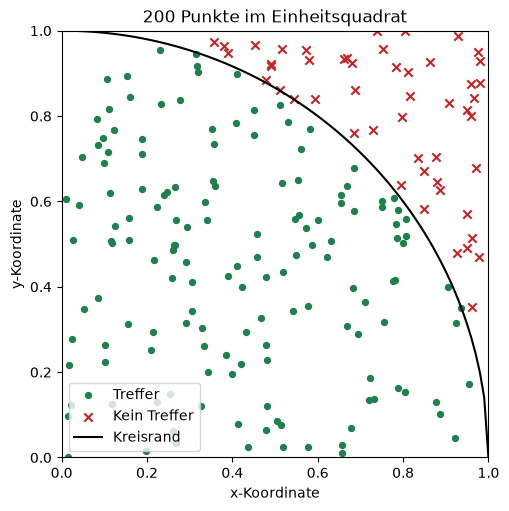

In [7]:
generator = Random(2026)
treffer_x, treffer_y = [], []
daneben_x, daneben_y = [], []
for versuch in range(200):
    koordinate_x = generator.random()
    koordinate_y = generator.random()
    if im_viertelkreis(koordinate_x, koordinate_y):
        treffer_x.append(koordinate_x)
        treffer_y.append(koordinate_y)
    else:
        daneben_x.append(koordinate_x)
        daneben_y.append(koordinate_y)

rand_x = [schritt / 100 for schritt in range(101)]
rand_y = [math.sqrt(1 - wert ** 2) for wert in rand_x]
figur, achse = plt.subplots(figsize=(5, 5), layout="constrained")
achse.scatter(treffer_x, treffer_y, color="#1c814a", s=18, label="Treffer")
achse.scatter(daneben_x, daneben_y, color="#c72426", marker="x", label="Kein Treffer")
achse.plot(rand_x, rand_y, color="black", label="Kreisrand")
achse.set(xlim=(0, 1), ylim=(0, 1), xlabel="x-Koordinate", ylabel="y-Koordinate",
          title="200 Punkte im Einheitsquadrat")
achse.set_aspect("equal")
achse.legend(loc="lower left")
plt.show()
plt.close(figur)

## 4. Eigenarbeit | 30 Minuten

**A04.1 | 15 Minuten:** Prüfen Sie (0.2, 0.3), (0.9, 0.9),
(0.6, 0.6) und (0.8, 0.7) zuerst auf Papier. Notieren Sie pro Punkt die
Quadratsumme und die Entscheidung, danach die Trefferquote und das
Pi-Rechenergebnis. Was kann diese feste Liste über Genauigkeit aussagen?

**Hilfe:** Erst quadrieren, dann addieren, dann mit 1 vergleichen.
Der Nenner zählt auch die Punkte außerhalb des Kreises.

**A04.2 | 15 Minuten:** Ergänzen Sie unterhalb eine eigene Codezelle.
Rufen Sie `schaetze_pi(anzahl, seed)` für 200 und 2000 Punkte mit den
Seeds 11, 12 und 13 auf. Halten Sie alle sechs Ergebnisse samt absoluter
Abweichung zu `math.pi` in einer Tabelle fest (Ausgaben genügen).
Liegt der größere Lauf bei diesen Paaren immer näher an pi?
Wäre dies eine Garantie für beliebige Seeds? Begründen Sie getrennt.

**Hilfe:** Beginnen Sie mit `schaetze_pi(200, 11)` und einem zweiten
Aufruf für denselben Seed. Manuelle Aufrufe sind erlaubt; verschachtelte
Schleifen werden nicht vorausgesetzt. Nur eine Größe gleichzeitig ändern.

## 5. Transfer | freiwillig nach dem Pflichtteil

**A04.3 | 10 Minuten:** Verwenden Sie das Rechteck 0 <= x <= 2,
0 <= y <= 1 und dieselbe Trefferregel. Leiten Sie den neuen Faktor ab,
der die Trefferquote in eine Pi-Schätzung umrechnet. Testen Sie danach
ein angepasstes Experiment. Die x-Koordinate entsteht mit
`2 * generator.random()`. Welche Fläche hat das gesamte Rechteck?

## Drei Dinge bleiben

1. Eine klare Ja/Nein-Regel definiert den Treffer.
2. Treffer geteilt durch alle Versuche ergibt die Quote.
3. Die Geometrie liefert den Faktor; der Zufall verursacht Schwankungen.

Rückblick Termin 3: Ein Seed macht den Lauf wiederholbar, nicht exakt.
Mehr Punkte verbessern die typische Genauigkeit, garantieren aber keine
kleinere Abweichung in jedem einzelnen Vergleich.
**Abschlussfrage:** Warum ist die Trefferzahl der falsche Nenner?
**Ausblick Termin 5:** Einzelne Punkte, ganze Läufe und wiederholte
Läufe sind verschiedene Ebenen. Wie messen wir die Schwankung?

In [25]:
# A04.1
def Quadratsumme(a, b):
    a = a ** 2
    b = b ** 2
    quadratsumme = a + b
    if quadratsumme <= 1:
        return True, quadratsumme
    else:
        return False, quadratsumme


punkte = [(0.2, 0.3), (0.9, 0.9), (0.6, 0.6), (0.8, 0.7)]

treffer = 0
for x, y in punkte:
    ist_treffer, quadratsumme = Quadratsumme(x, y)
    if ist_treffer:
        treffer += 1
    print(f"Punkt ({x}, {y}) | Quadratsumme: {quadratsumme:.2f} | Entscheidung: {'Treffer' if ist_treffer else 'Kein Treffer'}")

trefferquote = treffer / len(punkte)
pi_schaetzung = 4 * trefferquote

print()
print("Treffer:", treffer, "von", len(punkte))
print("Trefferquote:", trefferquote)
print("Pi-Schätzung:", pi_schaetzung)

Punkt (0.2, 0.3) | Quadratsumme: 0.13 | Entscheidung: Treffer
Punkt (0.9, 0.9) | Quadratsumme: 1.62 | Entscheidung: Kein Treffer
Punkt (0.6, 0.6) | Quadratsumme: 0.72 | Entscheidung: Treffer
Punkt (0.8, 0.7) | Quadratsumme: 1.13 | Entscheidung: Kein Treffer

Treffer: 2 von 4
Trefferquote: 0.5
Pi-Schätzung: 2.0


In [30]:
# A04.2
pi_200_11 = schaetze_pi(200, 11)
pi_200_12 = schaetze_pi(200, 12)
pi_200_13 = schaetze_pi(200, 13)

pi_2000_11 = schaetze_pi(2000, 11)
pi_2000_12 = schaetze_pi(2000, 12)
pi_2000_13 = schaetze_pi(2000, 13)

print(f"{'Punkte':>7} {'Seed':>5} {'Pi-Schätzung':>15} {'Absolute Abweichung':>22}")
print(f"{200:>7} {11:>5} {pi_200_11:>15.6f} {abs(pi_200_11 - math.pi):>22.6f}")
print(f"{200:>7} {12:>5} {pi_200_12:>15.6f} {abs(pi_200_12 - math.pi):>22.6f}")
print(f"{200:>7} {13:>5} {pi_200_13:>15.6f} {abs(pi_200_13 - math.pi):>22.6f}")
print(f"{2000:>7} {11:>5} {pi_2000_11:>15.6f} {abs(pi_2000_11 - math.pi):>22.6f}")
print(f"{2000:>7} {12:>5} {pi_2000_12:>15.6f} {abs(pi_2000_12 - math.pi):>22.6f}")
print(f"{2000:>7} {13:>5} {pi_2000_13:>15.6f} {abs(pi_2000_13 - math.pi):>22.6f}")

 Punkte  Seed    Pi-Schätzung    Absolute Abweichung
    200    11        3.060000               0.081593
    200    12        3.240000               0.098407
    200    13        3.280000               0.138407
   2000    11        3.126000               0.015593
   2000    12        3.106000               0.035593
   2000    13        3.178000               0.036407


In [31]:
# A04.3
def schaetze_pi_rechteck(anzahl, seed):
    generator = Random(seed)
    treffer = 0

    for versuch in range(anzahl):
        x = 2 * generator.random()
        y = generator.random()
        if im_viertelkreis(x, y):
            treffer += 1

    return 8 * treffer / anzahl


anzahl = 20000
seed = 2026
pi_schaetzung = schaetze_pi_rechteck(anzahl, seed)

print("Punkte:", anzahl, "Seed:", seed)
print("Pi-Schätzung:", pi_schaetzung)
print("Referenz:", math.pi)
print("Absolute Abweichung:", abs(pi_schaetzung - math.pi))

Punkte: 20000 Seed: 2026
Pi-Schätzung: 3.1732
Referenz: 3.141592653589793
Absolute Abweichung: 0.031607346410206905
